In [1]:
from ucimlrepo import fetch_ucirepo
import pandas as pd

ds = fetch_ucirepo(id=411)
print(ds.metadata["name"])

X = ds.data.features
y = ds.data.targets

print("X shape:", X.shape)
print("y columns:", y.columns.tolist())
print("X columns:", X.columns.tolist())
print("Text columns:", X.select_dtypes(include="object").columns.tolist())
print("Missing values:", X.isna().sum().sum())
for c in y.columns:
    print(c, y[c].value_counts().to_dict())

DatasetNotFoundError: "extention of Z-Alizadeh sani dataset" dataset (id=411) exists in the repository, but is not available for import. Please select a dataset from this list: https://archive.ics.uci.edu/datasets?skip=0&take=10&sort=desc&orderBy=NumHits&search=&Python=true

In [1]:
from sklearn.pipeline import make_pipeline
print("sklearn OK")

sklearn OK


In [2]:
from sklearn.pipeline import make_pipeline
from xgboost import XGBClassifier
print("sklearn and xgboost OK")

sklearn and xgboost OK


In [3]:
import pandas as pd, numpy as np
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate

data = pd.read_csv("../data/clean.csv")
TARGETS = ["CAD", "LAD", "LCX", "RCA"]
X = data.drop(columns=TARGETS)

models = {
    "LogReg": make_pipeline(StandardScaler(),
              LogisticRegression(max_iter=2000, random_state=42)),
    "RandomForest": RandomForestClassifier(n_estimators=300, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=150, max_depth=3, learning_rate=0.1,
                             random_state=42, eval_metric="logloss"),
}

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)
scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]

rows = []
for t in TARGETS:
    for name, m in models.items():
        r = cross_validate(m, X, data[t], cv=cv, scoring=scoring)
        row = {"target": t, "model": name}
        for s in scoring:
            v = r["test_" + s]
            row[s] = f"{v.mean():.3f} ± {v.std():.3f}"
        rows.append(row)

results = pd.DataFrame(rows)
print(results.to_string(index=False))
results.to_csv("../data/cv_results.csv", index=False)


target        model      accuracy     precision        recall            f1       roc_auc
   CAD       LogReg 0.844 ± 0.034 0.895 ± 0.029 0.886 ± 0.041 0.890 ± 0.025 0.909 ± 0.026
   CAD RandomForest 0.873 ± 0.041 0.882 ± 0.037 0.952 ± 0.034 0.915 ± 0.027 0.923 ± 0.031
   CAD      XGBoost 0.858 ± 0.037 0.890 ± 0.033 0.915 ± 0.039 0.902 ± 0.025 0.899 ± 0.040
   LAD       LogReg 0.725 ± 0.046 0.772 ± 0.050 0.759 ± 0.080 0.762 ± 0.045 0.805 ± 0.053
   LAD RandomForest 0.786 ± 0.042 0.785 ± 0.046 0.880 ± 0.061 0.827 ± 0.034 0.851 ± 0.045
   LAD      XGBoost 0.751 ± 0.034 0.777 ± 0.037 0.810 ± 0.056 0.791 ± 0.030 0.814 ± 0.044
   LCX       LogReg 0.625 ± 0.046 0.532 ± 0.082 0.467 ± 0.082 0.492 ± 0.065 0.638 ± 0.056
   LCX RandomForest 0.660 ± 0.066 0.610 ± 0.129 0.373 ± 0.101 0.460 ± 0.110 0.716 ± 0.073
   LCX      XGBoost 0.675 ± 0.065 0.603 ± 0.104 0.516 ± 0.095 0.554 ± 0.091 0.729 ± 0.078
   RCA       LogReg 0.660 ± 0.043 0.550 ± 0.057 0.527 ± 0.125 0.532 ± 0.083 0.694 ± 0.050
   RCA Ran

In [4]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

tries = {
    "RF balanced": RandomForestClassifier(n_estimators=300, min_samples_leaf=3,
                     class_weight="balanced", random_state=42),
    "LogReg balanced C=0.1": make_pipeline(StandardScaler(),
                     LogisticRegression(C=0.1, class_weight="balanced",
                                        max_iter=2000, random_state=42)),
}
for t in ["LCX", "RCA"]:
    for name, m in tries.items():
        r = cross_validate(m, X, data[t], cv=cv, scoring=["recall", "roc_auc"])
        print(t, name,
              f"recall {r['test_recall'].mean():.3f}",
              f"auc {r['test_roc_auc'].mean():.3f}")

LCX RF balanced recall 0.605 auc 0.725
LCX LogReg balanced C=0.1 recall 0.585 auc 0.651
RCA RF balanced recall 0.555 auc 0.718
RCA LogReg balanced C=0.1 recall 0.635 auc 0.713


In [5]:
import os, json, joblib
from sklearn.ensemble import RandomForestClassifier

final_models = {
    "CAD": RandomForestClassifier(n_estimators=300, random_state=42),
    "LAD": RandomForestClassifier(n_estimators=300, random_state=42),
    "LCX": RandomForestClassifier(n_estimators=300, min_samples_leaf=3,
                                  class_weight="balanced", random_state=42),
    "RCA": RandomForestClassifier(n_estimators=300, min_samples_leaf=3,
                                  class_weight="balanced", random_state=42),
}

out = "../backend/saved_models"
os.makedirs(out, exist_ok=True)

for t, m in final_models.items():
    m.fit(X, data[t])
    joblib.dump(m, f"{out}/{t.lower()}_model.joblib")

json.dump(list(X.columns), open(f"{out}/feature_columns.json", "w"))
print(os.listdir(out))

['cad_model.joblib', 'feature_columns.json', 'lad_model.joblib', 'lcx_model.joblib', 'rca_model.joblib']


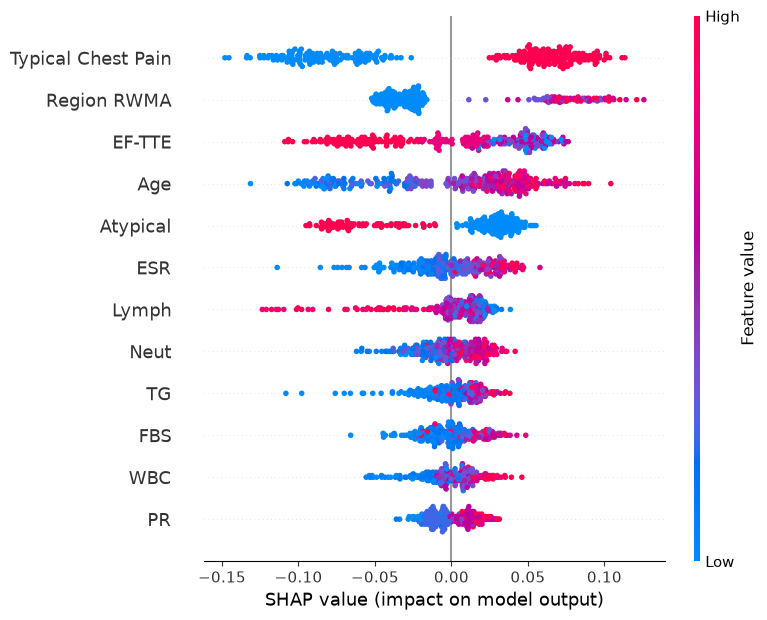

In [6]:
import shap, joblib, numpy as np
import matplotlib.pyplot as plt

folder = "../backend/saved_models"

def get_shap(target):
    model = joblib.load(f"{folder}/{target.lower()}_model.joblib")
    explainer = shap.TreeExplainer(model)
    sv = explainer.shap_values(X)
    # different SHAP versions return different shapes; keep the "stenotic" class
    if isinstance(sv, list):
        sv = sv[1]
    elif sv.ndim == 3:
        sv = sv[:, :, 1]
    return model, explainer, sv

model, explainer, sv = get_shap("LAD")

# 1. Overall picture: which features matter most across all patients
shap.summary_plot(sv, X, max_display=12)

In [7]:
def explain_patient(target, i, top=8):
    model, explainer, sv = get_shap(target)
    prob = model.predict_proba(X.iloc[[i]])[0][1]
    contrib = (pd.DataFrame({"feature": X.columns,
                             "patient_value": X.iloc[i].values,
                             "shap": sv[i]})
               .assign(abs_shap=lambda d: d["shap"].abs())
               .sort_values("abs_shap", ascending=False)
               .head(top).drop(columns="abs_shap"))
    print(f"{target} predicted risk: {prob:.0%}")
    print(contrib.to_string(index=False))

explain_patient("LAD", 0)

LAD predicted risk: 79%
           feature  patient_value      shap
Typical Chest Pain            0.0 -0.059025
          Atypical            0.0  0.038154
     St Depression            1.0  0.031764
        Tinversion            1.0  0.031384
                TG          250.0  0.029898
       Region RWMA            0.0 -0.028244
                 K            4.7  0.024555
                PR           80.0  0.021995


In [8]:
ev = explainer.expected_value
base = float(np.atleast_1d(ev)[-1])
print("average risk:", round(base, 3))
print("average + all pushes:", round(base + sv[0].sum(), 3))
print("model's prediction:", round(model.predict_proba(X.iloc[[0]])[0][1], 3))
print("actual LAD label for patient 0:", data.loc[0, "LAD"])

average risk: 0.587
average + all pushes: 0.79
model's prediction: 0.79
actual LAD label for patient 0: 1


In [10]:
binary_cols = [c for c in X.columns if set(X[c].unique()) <= {0, 1}]

def label(feat, val):
    if feat == "Sex":
        return "Male" if val == 1 else "Female"
    if feat in binary_cols:
        return f"{feat} {'present' if val == 1 else 'absent'}"
    return f"{feat} = {val:g}"

def explain_text(target, i, top=4):
    model, explainer, sv = get_shap(target)
    prob = model.predict_proba(X.iloc[[i]])[0][1]
    d = (pd.DataFrame({"feature": X.columns,
                       "value": X.iloc[i].values, "shap": sv[i]})
         .assign(a=lambda d: d.shap.abs())
         .sort_values("a", ascending=False).head(top))
    up = [label(r.feature, r.value) for r in d.itertuples() if r.shap > 0]
    down = [label(r.feature, r.value) for r in d.itertuples() if r.shap < 0]
    s = f"Predicted {target} stenosis risk: {prob:.0%}. "
    if up:   s += "Raising the risk: " + "; ".join(up) + ". "
    if down: s += "Lowering the risk: " + "; ".join(down) + ". "
    return s + "These show how the model reasoned, not a medical cause."

print(explain_text("LAD", 0))

Predicted LAD stenosis risk: 79%. Raising the risk: Atypical absent; St Depression present; Tinversion present. Lowering the risk: Typical Chest Pain absent. These show how the model reasoned, not a medical cause.


In [11]:
import json, joblib, numpy as np

folder = "../backend/saved_models"
binary = [c for c in X.columns if set(X[c].unique()) <= {0, 1}]
defaults = X.median().to_dict()   # used when a value is not provided

cad = joblib.load(f"{folder}/cad_model.joblib")
p = cad.predict_proba(X)[:, 1]
picks = {"low": int(np.argmin(p)),
         "medium": int(np.argmin(np.abs(p - 0.5))),
         "high": int(np.argmax(p))}
demo = {k: X.iloc[i].astype(float).to_dict() for k, i in picks.items()}

json.dump({"defaults": defaults, "binary": binary, "demo": demo},
          open(f"{folder}/meta.json", "w"))
print(picks)

{'low': 261, 'medium': 213, 'high': 277}


In [12]:
import json
folder = "../backend/saved_models"
meta = json.load(open(f"{folder}/meta.json"))

for c in meta["binary"]:
    meta["defaults"][c] = 0.0

json.dump(meta, open(f"{folder}/meta.json", "w"))
print({c: meta["defaults"][c] for c in ["Sex", "Typical Chest Pain", "Age", "BP"]})

{'Sex': 0.0, 'Typical Chest Pain': 0.0, 'Age': 58.0, 'BP': 130.0}


In [ ]:
from sklearn.ensemble import RandomForestClassifier

cfg = {
    "CAD": RandomForestClassifier(n_estimators=300, random_state=42),
    "LAD": RandomForestClassifier(n_estimators=300, random_state=42),
    "LCX": RandomForestClassifier(n_estimators=300, min_samples_leaf=3,
                                  class_weight="balanced", random_state=42),
    "RCA": RandomForestClassifier(n_estimators=300, min_samples_leaf=3,
                                  class_weight="balanced", random_state=42),
}

from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss
import matplotlib.pyplot as plt

skf = StratifiedKFold(5, shuffle=True, random_state=42)
fig, ax = plt.subplots()
for t, m in cfg.items():
    p = cross_val_predict(m, X, data[t], cv=skf, method="predict_proba")[:, 1]
    fx, mp = calibration_curve(data[t], p, n_bins=6)
    ax.plot(mp, fx, marker="o", label=f"{t} (Brier {brier_score_loss(data[t], p):.2f})")
ax.plot([0, 1], [0, 1], "--", color="gray")
ax.set_xlabel("Predicted risk"); ax.set_ylabel("Observed fraction"); ax.legend()
plt.savefig("../data/calibration.png", dpi=150); plt.show()